In [11]:
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_core.documents import Document

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # backend/ 를 import 경로에 추가

from agent import schemas

In [12]:
from datetime import date

MAX_RETRY = 2

def search_documents(state: schemas.FundamentalState) -> dict:
    return {"vector_docs": []}

def search_web(state: schemas.FundamentalState) -> dict:
    return {"web_docs": []}

def unify_documents(state: schemas.FundamentalState) -> dict:
    return {"context": []}

def relevance_check(state: schemas.FundamentalState) -> dict:
    return {"relevance": "no"}

def query_rewrite(state: schemas.FundamentalState) -> dict:
    return {
        "question": state["question"] + " (rewrite)",
        "retry_count": state["retry_count"] + 1
        }

def fundamental_summary(state: schemas.FundamentalState) -> dict:
    return {
        "summary": schemas.FundamentalSummary(
            business_overview="(test) 사업 개요",
            stated_risks="(test) 리스크",
            management_outlook="(test) 경영진 전망",
            recent_issues="(test) 최근 이슈",
            sources=[],
        )
    }

def route(state: schemas.FundamentalState) -> str:
    if state["relevance"] == "yes" or state["retry_count"] >= MAX_RETRY:
        return "relevance"
    return "no_relevance"

In [ ]:
builder = StateGraph(schemas.FundamentalState)

builder.add_node("search_documents", search_documents)
builder.add_node("unify_documents", unify_documents)
builder.add_node("search_web", search_web)
builder.add_node("relevance_check", relevance_check)
builder.add_node("query_rewrite", query_rewrite)
builder.add_node("fundamental_summary", fundamental_summary)

In [14]:
builder.add_edge(START, "search_documents")
builder.add_edge(START, "search_web")

builder.add_edge(["search_documents", "search_web"], "unify_documents")

builder.add_edge(["unify_documents"], "relevance_check")

builder.add_conditional_edges(
    "relevance_check",
    route,
    {"relevance": "fundamental_summary", "no_relevance": "query_rewrite"},
)

builder.add_edge("query_rewrite", "search_web")
builder.add_edge("query_rewrite", "search_documents")


builder.add_edge("fundamental_summary", END)

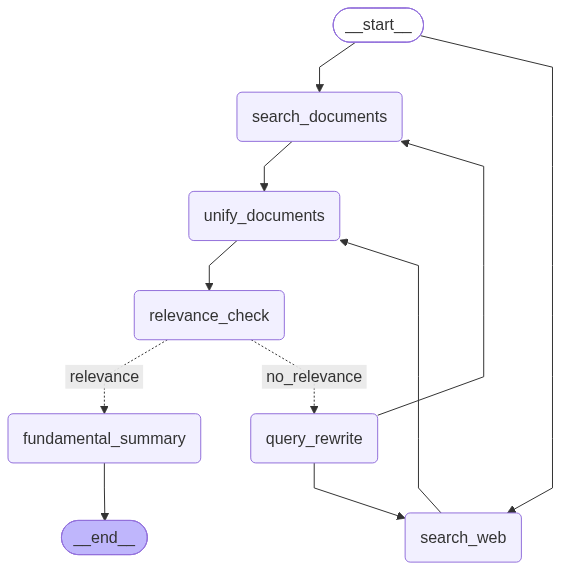

In [15]:
def showGraph(graph):
    # Show the graph
    from IPython.display import Image, display
    display(Image(graph.get_graph(xray=True).draw_mermaid_png()))
    
graph = builder.compile()
showGraph(graph)

In [16]:
# 셀 5
inp = {
    "ticker": "AAPL",
    "market": "US",
    "as_of_date": date(2026, 10, 20),
    "question": "AAPL 사업 구조, 주요 리스크, 경영진 전망",
    "vector_docs": [],
    "web_docs": [],
    "context": [],
    "retry_count": 0,
    "summary": None,
}

for update in graph.stream(inp, stream_mode="updates"):
    print(list(update.keys()))

result = graph.invoke(inp)
result["summary"]

['search_documents']
['search_web']
['unify_documents']
['relevance_check']
['query_rewrite']
['search_documents']
['search_web']
['unify_documents']
['relevance_check']
['query_rewrite']
['search_documents']
['search_web']
['unify_documents']
['relevance_check']
['fundamental_summary']


FundamentalSummary(business_overview='(test) 사업 개요', stated_risks='(test) 리스크', management_outlook='(test) 경영진 전망', recent_issues='(test) 최근 이슈', sources=[])

In [17]:
from datetime import date
from agent.graph import build_graph
import agent.nodes.past_decision as pd

graph = build_graph()

pd.HAS_PAST = False
inp = {"ticker": "MSFT", "market": "US", "as_of_date": date(2026, 10, 20)}
for update in graph.stream(inp, stream_mode="updates"):
    print(list(update.keys()))
graph.invoke(inp)["report"]

['past_decision']
['quant']
['fundamental']
['write_report']
['old_exist']


Report(investment_thesis='(test) 투자 논리', risks='(test) 리스크', consensus_gap='(test) 컨센서스 대비 차이', thesis_breakers='(test) 철회 조건', sources=[], ticker='MSFT', market='US', as_of_date=datetime.date(2026, 10, 20), quant_snapshot=QuantSnapshot(ticker='MSFT', market='US', as_of_date=datetime.date(2026, 10, 20), currency='USD', sector='Technology', industry='Consumer Electronics', market_cap=3400000000000.0, price=230.0, change_pct=1.2, volume=52000000, per=31.5, forward_per=28.0, pbr=45.0, roe=150.0, roa=28.0, profit_margin=24.0, dividend_yield=None, ma_50=225.0, ma_200=210.0, volatility_60d=22.0, return_6m=8.5, return_12m=15.0, analyst_target_price=None, eps_estimate=1.6, eps_actual=1.65, eps_surprise_pct=3.125), past_decision_review=None)